Physics-Based Modeling of an Iron-Air Battery

Project Overview

This project develops a simplified, physics-based model of an iron-air battery using Python. The objective is to explore how electrochemical behavior, oxygen mass transport, and thermal effects interact during battery discharge.

The model uses coupled differential equations to simulate battery state of charge, terminal voltage, oxygen concentration, and temperature over time.

Model Components

Electrochemical model: Estimates open-circuit voltage, activation overpotential, concentration overpotential, and ohmic losses.

Oxygen transport model: Represents oxygen consumption during discharge and replenishment through a simplified mass-transfer relationship.

Thermal model: Estimates heat generation from electrochemical losses and heat dissipation to the surroundings.

Integrated simulation: Solves the coupled system of differential equations using SciPy's solve_ivp.

Tools and Libraries

Python

NumPy

SciPy

Matplotlib

Scope and Assumptions

This is an independent, exploratory modeling project. It uses illustrative parameter values and simplified relationships to demonstrate a framework for coupled electrochemical, mass-transfer, and thermal analysis.

The model is not a validated representation of a commercial iron-air battery or of Form Energy's proprietary technology. Its predictions should not be interpreted as experimentally verified performance.

Project Objective

The project provides a foundation for investigating how operating current, oxygen availability, internal resistance, and thermal conditions can influence battery discharge behavior. Future work can incorporate literature-supported parameters, experimental data, model validation, and sensitivity analysis.

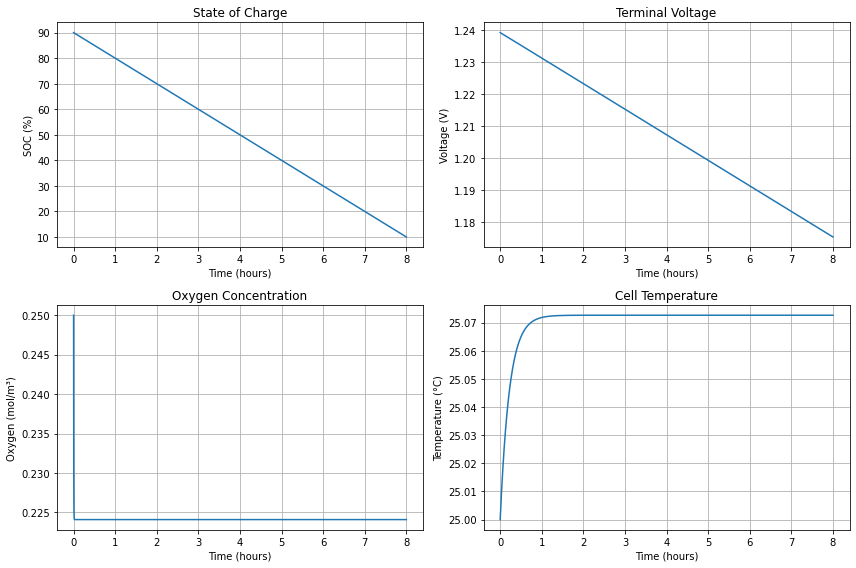

SIMULATION SUMMARY
------------------------------
Final SOC: 10.00%
Final voltage: 1.175 V
Maximum temperature: 25.07 °C
Minimum oxygen concentration: 0.2241 mol/m³
Simulation stopped because: Simulation duration reached


In [9]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


# =====================================================
# 1. PHYSICAL CONSTANTS
# =====================================================

F = 96485.0       # Faraday constant (C/mol)
R = 8.314         # Universal gas constant (J/mol/K)
T_REF = 298.15    # Reference temperature (K)


# =====================================================
# 2. ILLUSTRATIVE CELL PARAMETERS
# Replace these with literature-supported or fitted values.
# =====================================================

P = {
    # Electrochemical parameters
    "capacity_Ah": 100.0,
    "U_ref": 1.28,
    "soc_slope": 0.08,
    "R_internal": 0.005,
    "i0_ref": 5.0,
    "activation_energy": 20000.0,
    "n_kinetic": 2,

    # Oxygen transport parameters
    "oxygen_bulk": 0.25,          # mol/m^3
    "oxygen_initial": 0.25,       # mol/m^3
    "kla": 0.10,                  # 1/s
    "electrolyte_volume": 0.01,   # m^3
    "electrode_area": 20.0,       # m^2
    "mass_transfer_coeff": 1e-3, # m/s

    # Thermal parameters
    "mass": 10.0,                 # kg
    "heat_capacity": 800.0,      # J/(kg K)
    "heat_transfer": 10.0,       # W/(m^2 K)
    "surface_area": 1.0,         # m^2
    "ambient_temp": 298.15,      # K
}


# =====================================================
# 3. ELECTROCHEMICAL MODEL
# =====================================================

def calculate_voltage(soc, oxygen, temperature, current, p):

    # Assumed open-circuit voltage relationship
    U_ocv = p["U_ref"] + p["soc_slope"] * (soc - 0.5)

    # Temperature-dependent exchange current
    i0 = p["i0_ref"] * np.exp(
        -p["activation_energy"] / R
        * (1.0 / temperature - 1.0 / T_REF)
    )

    # Butler-Volmer activation overpotential
    eta_act = (
        2.0 * R * temperature / (p["n_kinetic"] * F)
        * np.arcsinh(current / (2.0 * i0))
    )

    # Oxygen limiting current
    oxygen_safe = max(oxygen, 1e-8)

    I_lim = (
        4.0 * F
        * p["electrode_area"]
        * p["mass_transfer_coeff"]
        * oxygen_safe
    )

    # Concentration overpotential
    # The clipping avoids a mathematical singularity at I = I_lim.
    ratio = np.clip(current / I_lim, 0.0, 0.995)

    eta_conc = (
        -R * temperature / (4.0 * F)
        * np.log(1.0 - ratio)
    )

    # Ohmic voltage loss
    ohmic_loss = current * p["R_internal"]

    # Terminal voltage
    voltage = U_ocv - eta_act - eta_conc - ohmic_loss

    return voltage, U_ocv, eta_act, eta_conc, I_lim


# =====================================================
# 4. COUPLED DIFFERENTIAL EQUATIONS
#
# State variables:
# y[0] = State of charge
# y[1] = Oxygen concentration (mol/m^3)
# y[2] = Temperature (K)
# =====================================================

def battery_odes(t, y, current, p):

    soc, oxygen, temperature = y

    voltage, U_ocv, eta_act, eta_conc, I_lim = (
        calculate_voltage(
            soc, oxygen, temperature, current, p
        )
    )

    # ---------------------------------------------
    # A. State of charge balance
    # ---------------------------------------------

    dSOC_dt = -current / (3600.0 * p["capacity_Ah"])

    # ---------------------------------------------
    # B. Oxygen mass balance
    # ---------------------------------------------

    oxygen_replenishment = (
        p["kla"] * (p["oxygen_bulk"] - oxygen)
    )

    oxygen_consumption = (
        current / (4.0 * F * p["electrolyte_volume"])
    )

    dO2_dt = oxygen_replenishment - oxygen_consumption

    # ---------------------------------------------
    # C. Thermal energy balance
    # ---------------------------------------------

    # Approximate irreversible heat generation
    heat_generated = current * (U_ocv - voltage)

    heat_removed = (
        p["heat_transfer"]
        * p["surface_area"]
        * (temperature - p["ambient_temp"])
    )

    dT_dt = (
        heat_generated - heat_removed
    ) / (p["mass"] * p["heat_capacity"])

    return [dSOC_dt, dO2_dt, dT_dt]


# =====================================================
# 5. TERMINATION EVENTS
# =====================================================

def soc_depleted(t, y, current, p):
    return y[0]

soc_depleted.terminal = True
soc_depleted.direction = -1


def oxygen_depleted(t, y, current, p):
    return y[1] - 1e-8

oxygen_depleted.terminal = True
oxygen_depleted.direction = -1


def transport_limited(t, y, current, p):

    I_lim = (
        4.0 * F
        * p["electrode_area"]
        * p["mass_transfer_coeff"]
        * max(y[1], 1e-8)
    )

    return I_lim - current

transport_limited.terminal = True
transport_limited.direction = -1


# =====================================================
# 6. SIMULATION FUNCTION
# =====================================================

def simulate_battery(
    current=10.0,
    duration_hours=8.0,
    p=None
):

    # Use default parameters unless a custom dictionary is supplied
    if p is None:
        p = P

    # Validate inputs
    if current <= 0:
        raise ValueError("Current must be positive for discharge.")

    if duration_hours <= 0:
        raise ValueError("Simulation duration must be positive.")

    if p["capacity_Ah"] <= 0:
        raise ValueError("Battery capacity must be positive.")

    # Initial conditions
    initial_conditions = [
        0.90,                  # Initial SOC
        p["oxygen_initial"],   # Initial oxygen concentration
        p["ambient_temp"]      # Initial temperature
    ]

    # Check whether the requested current is feasible initially
    initial_I_lim = (
        4.0 * F
        * p["electrode_area"]
        * p["mass_transfer_coeff"]
        * max(p["oxygen_initial"], 1e-8)
    )

    if current >= initial_I_lim:
        raise ValueError(
            "Requested current is at or above the initial "
            "oxygen-transport limiting current."
        )

    # Solve the coupled differential equations
    solution = solve_ivp(
        battery_odes,
        (0, duration_hours * 3600.0),
        initial_conditions,
        args=(current, p),
        events=(
            soc_depleted,
            oxygen_depleted,
            transport_limited
        ),
        max_step=30.0,
        rtol=1e-6,
        atol=1e-8
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    # Extract state variables
    time = solution.t
    soc = np.clip(solution.y[0], 0.0, 1.0)
    oxygen = np.maximum(solution.y[1], 1e-8)
    temperature = solution.y[2]

    # Calculate voltage and overpotentials at every time point
    voltage = []
    eta_act_values = []
    eta_conc_values = []
    limiting_current = []

    for i in range(len(time)):

        result = calculate_voltage(
            soc[i],
            oxygen[i],
            temperature[i],
            current,
            p
        )

        voltage.append(result[0])
        eta_act_values.append(result[2])
        eta_conc_values.append(result[3])
        limiting_current.append(result[4])

    # Identify why the simulation stopped
    event_names = [
        "SOC depleted",
        "Oxygen depleted",
        "Oxygen transport limited"
    ]

    stop_reason = "Simulation duration reached"

    for i, event_times in enumerate(solution.t_events):
        if len(event_times) > 0:
            stop_reason = event_names[i]
            break

    return {
        "time_s": time,
        "soc": soc,
        "oxygen": oxygen,
        "temperature": temperature,
        "voltage": np.array(voltage),
        "eta_act": np.array(eta_act_values),
        "eta_conc": np.array(eta_conc_values),
        "I_lim": np.array(limiting_current),
        "stop_reason": stop_reason
    }


# =====================================================
# 7. RUN SIMULATION
# =====================================================

if __name__ == "__main__":

    results = simulate_battery(
        current=10.0,
        duration_hours=8.0
    )

    time_hours = results["time_s"] / 3600.0

    # Create dashboard-style plots
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    # State of charge
    axes[0, 0].plot(
        time_hours,
        results["soc"] * 100
    )
    axes[0, 0].set_title("State of Charge")
    axes[0, 0].set_ylabel("SOC (%)")

    # Terminal voltage
    axes[0, 1].plot(
        time_hours,
        results["voltage"]
    )
    axes[0, 1].set_title("Terminal Voltage")
    axes[0, 1].set_ylabel("Voltage (V)")

    # Oxygen concentration
    axes[1, 0].plot(
        time_hours,
        results["oxygen"]
    )
    axes[1, 0].set_title("Oxygen Concentration")
    axes[1, 0].set_ylabel("Oxygen (mol/m³)")

    # Temperature
    axes[1, 1].plot(
        time_hours,
        results["temperature"] - 273.15
    )
    axes[1, 1].set_title("Cell Temperature")
    axes[1, 1].set_ylabel("Temperature (°C)")

    for ax in axes.flat:
        ax.set_xlabel("Time (hours)")
        ax.grid(True)

    plt.tight_layout()
    plt.show()

    # Print simulation summary
    print("SIMULATION SUMMARY")
    print("------------------------------")
    print(f"Final SOC: {results['soc'][-1] * 100:.2f}%")
    print(f"Final voltage: {results['voltage'][-1]:.3f} V")
    print(
        "Maximum temperature: "
        f"{np.max(results['temperature']) - 273.15:.2f} °C"
    )
    print(
        "Minimum oxygen concentration: "
        f"{np.min(results['oxygen']):.4f} mol/m³"
    )
    print(f"Simulation stopped because: {results['stop_reason']}")
